In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import matplotlib.ticker as ticker
import matplotlib.cm as cm
from warnings import filterwarnings
filterwarnings ('ignore')


In [2]:
# set color profsional theme
try:
    plt.style.use('seaborn-whitegrid')
except OSError:
    plt.style.use('default')
sns.set_palette("viridis")

virdis_colors = cm.viridis(np.linspace(0 , 1 ,5 ))
primary_color = virdis_colors[0]
secondary_color = virdis_colors[1]
tertiary_color = virdis_colors[2]
danger_color ='#800000'
neutral_color = virdis_colors[4]
custom_palette   = virdis_colors

In [3]:
df = pd.read_csv('DataCoSupplyChainDataset.csv',encoding='latin-1')

In [4]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id',
       'Customer Lname', 'Customer Password', 'Customer Segment',
       'Customer State', 'Customer Street', 'Customer Zipcode',
       'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market',
       'Order City', 'Order Country', 'Order Customer Id',
       'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id',
       'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id',
       'Order Item Product Price', 'Order Item Profit Ratio',
       'Order Item Quantity', 'Sales', 'Order Item Total',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Order Zipcode', 'Product Card Id', 'Product Category Id',
       'Product De

In [5]:
print('rows,cols:',df.shape)
print('\ncolumns')
print(df.columns.tolist())
print('\nNum duplicates:',df.duplicated().sum())
print('\nMissing Values (top 20):')
print(df.isna().sum().sort_values(ascending=False).head(20))

rows,cols: (13920, 53)

columns
['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)', 'Benefit per order', 'Sales per customer', 'Delivery Status', 'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City', 'Customer Country', 'Customer Email', 'Customer Fname', 'Customer Id', 'Customer Lname', 'Customer Password', 'Customer Segment', 'Customer State', 'Customer Street', 'Customer Zipcode', 'Department Id', 'Department Name', 'Latitude', 'Longitude', 'Market', 'Order City', 'Order Country', 'Order Customer Id', 'order date (DateOrders)', 'Order Id', 'Order Item Cardprod Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Id', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Sales', 'Order Item Total', 'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status', 'Order Zipcode', 'Product Card Id', 'Product Category Id', 'Product Description', 'Product Image', 'Product Name', 'Product Price', 'Product S

In [6]:
# Data cleaning

columns_to_drop =[
    'Product Description',
    'Prduct Image ',
    'Customer Email',
    'Customer Password',
    'Latitude',
    'Longitude',
    'Product Status',
    'Order Zipcode',
    'Shipping Zipcode',
    'Customer Fname',
    'Customer Lname',
    'Customer Street',
    'Customer Zipcode',
    'Oreder Zipcode',
    'Order Item Cardprod Id',
    'Product Card Id',
    'Order ID',
    'Order Customer ID',
    'Order Item Discount',
    'Order Item Discount Rate',
    'Order Item Product Price',
    'Order Item Quantity',
    'Order Item Total',
    'Product Card Id',
    'Product Category Id',
    'Product Description',
    'Product Image',
    'Product Name',
    'Product Status',
    'Shipping Mode'
]

# Drop columns, ignoring errors if some columns do not exist
df = df.drop(columns=columns_to_drop, errors='ignore')

# Filter out Shipping Canceled
df = df[df['Delivery Status'] != 'Shipping Canceled']

# Convert date columns using the exact column names present in the dataset
for c in ['order date (DateOrders)', 'shipping date (DateOrders)']:
    if c in df.columns:
        df[c] = pd.to_datetime(df[c], errors='coerce', dayfirst=False)


print('rows,cols',df.shape)
print('\nMissing Values (top 5):')
print(df.isna().sum().sort_values(ascending=False).head(5))


rows,cols (13920, 31)

Missing Values (top 5):
Customer Segment          1
Department Id             1
Customer State            1
Order Region              1
Order Profit Per Order    1
dtype: int64


In [ ]:
df.head(5)

,Type,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Delivery Status,Late_delivery_risk,Category Id,Category Name,Customer City,...,Order Id,Order Item Id,Order Item Profit Ratio,Sales,Order Profit Per Order,Order Region,Order State,Order Status,Product Price,shipping date (DateOrders)
0,DEBIT,3,4,91.250000,314.640015,Advance shipping,0,73,Sporting Goods,Caguas,...,77202,180517,0.29,327.75,91.250000,Southeast Asia,Java Occidental,COMPLETE,327.75,2018-02-03 22:56:00
1,TRANSFER,5,4,-249.089996,311.359985,Late delivery,1,73,Sporting Goods,Caguas,...,75939,179254,-0.80,327.75,-249.089996,South Asia,Rajastán,PENDING,327.75,2018-01-18 12:27:00
2,CASH,4,4,-247.779999,309.720001,Shipping on time,0,73,Sporting Goods,San Jose,...,75938,179253,-0.80,327.75,-247.779999,South Asia,Rajastán,CLOSED,327.75,2018-01-17 12:06:00
3,DEBIT,3,4,22.860001,304.809998,Advance shipping,0,73,Sporting Goods,Los Angeles,...,75937,179252,0.08,327.75,22.860001,Oceania,Queensland,COMPLETE,327.75,2018-01-16 11:45:00
4,PAYMENT,2,4,134.210007,298.250000,Advance shipping,0,73,Sporting Goods,Caguas,...,75936,179251,0.45,327.75,134.210007,Oceania,Queensland,PENDING_PAYMENT,327.75,2018-01-15 11:24:00


In [7]:
for col in df.columns:
  if df[col].nunique() < 10:
    print(f'\n{col} value counts:')
    print(df[col].value_counts())


Type value counts:
Type
DEBIT       6274
TRANSFER    3916
PAYMENT     2053
CASH        1677
Name: count, dtype: int64

Days for shipping (real) value counts:
Days for shipping (real)
2    4064
6    2452
4    2447
3    2362
5    2337
1     141
0     117
Name: count, dtype: int64

Days for shipment (scheduled) value counts:
Days for shipment (scheduled)
4    9138
2    2926
1    1598
0     258
Name: count, dtype: int64

Delivery Status value counts:
Delivery Status
Late delivery        7379
Advance shipping     3492
Shipping on time     2429
Shipping canceled     620
Name: count, dtype: int64

Late_delivery_risk value counts:
Late_delivery_risk
1    7379
0    6541
Name: count, dtype: int64

Customer Country value counts:
Customer Country
Puerto Rico    7487
EE. UU.        6433
Name: count, dtype: int64

Customer Segment value counts:
Customer Segment
Consumer       6195
Corporate      4740
Home Office    2984
Name: count, dtype: int64

Market value counts:
Market
Europe          4515
Pac

In [8]:
df['Order Proccessing Time']=(df['shipping date (DateOrders)']-df['order date (DateOrders)']).dt.days
df['Delay']=df['Order Proccessing Time'] - df['Days for shipment (scheduled)']
df['IS_Delayed']=df['Delay']>0
df['Order_month'] = df['order date (DateOrders)'].dt.month
df['Order_day'] = df['order date (DateOrders)'].dt.day_name()
df['Order_hour'] = df['order date (DateOrders)'].dt.hour
df.describe()

,Days for shipping (real),Days for shipment (scheduled),Benefit per order,Sales per customer,Late_delivery_risk,Category Id,Customer Id,Department Id,Order Customer Id,order date (DateOrders),...,Order Item Id,Order Item Profit Ratio,Sales,Order Profit Per Order,Product Price,shipping date (DateOrders),Order Proccessing Time,Delay,Order_month,Order_hour
count,13920.000000,13920.000000,13920.000000,13920.000000,13920.000000,13920.000000,13920.000000,13919.000000,13919.000000,13919,...,13919.000000,13919.000000,13919.000000,13919.000000,13919.000000,13919,13919.000000,13919.000000,13919.000000,13919.000000
mean,3.702586,3.161063,21.313542,182.722125,0.530101,26.143032,7014.956968,4.626051,7015.331346,2016-06-14 20:10:40.735685120,...,90428.441914,0.120529,203.701785,21.312126,122.884987,2016-06-18 13:01:20.264386816,3.692578,0.531576,6.504059,11.528414
min,0.000000,0.000000,-3366.000000,8.470000,0.000000,2.000000,1.000000,2.000000,1.000000,2015-01-01 03:51:00,...,35.000000,-2.750000,11.290000,-3366.000000,11.290000,2015-01-04 03:51:00,0.000000,-2.000000,1.000000,0.000000
25%,2.000000,2.000000,6.810000,100.000000,0.000000,17.000000,3406.750000,4.000000,3408.500000,2015-09-18 07:51:30,...,44558.000000,0.080000,119.980003,6.810000,50.000000,2015-09-23 00:04:00,2.000000,-1.000000,3.000000,5.000000
50%,4.000000,4.000000,30.580000,151.169998,1.000000,24.000000,6737.000000,4.000000,6737.000000,2016-05-19 18:12:00,...,86361.000000,0.270000,179.970001,30.570000,59.990002,2016-05-23 14:42:00,4.000000,1.000000,7.000000,12.000000
75%,5.000000,4.000000,64.052502,251.979996,1.000000,29.000000,10074.500000,5.000000,10075.000000,2017-03-03 08:00:00,...,135714.000000,0.360000,299.950012,64.055000,129.990005,2017-03-06 17:48:00,5.000000,2.000000,9.000000,17.000000
max,6.000000,4.000000,684.000000,1759.989990,1.000000,76.000000,20755.000000,12.000000,20755.000000,2018-01-31 22:56:00,...,180517.000000,0.500000,1999.989990,684.000000,1999.989990,2018-02-06 04:43:00,6.000000,4.000000,12.000000,23.000000
std,1.532105,1.211130,113.847419,128.518919,0.499111,16.225024,4464.173700,1.609280,4464.115540,NaN,...,52970.346317,0.466393,142.934050,113.851386,141.382399,NaN,1.553092,1.562601,3.495173,6.943682


In [9]:
df['IS_Delayed'].value_counts()


,count
IS_Delayed,
True,7552
False,6368


In [10]:
df.columns

Index(['Type', 'Days for shipping (real)', 'Days for shipment (scheduled)',
       'Benefit per order', 'Sales per customer', 'Delivery Status',
       'Late_delivery_risk', 'Category Id', 'Category Name', 'Customer City',
       'Customer Country', 'Customer Id', 'Customer Segment', 'Customer State',
       'Department Id', 'Department Name', 'Market', 'Order City',
       'Order Country', 'Order Customer Id', 'order date (DateOrders)',
       'Order Id', 'Order Item Id', 'Order Item Profit Ratio', 'Sales',
       'Order Profit Per Order', 'Order Region', 'Order State', 'Order Status',
       'Product Price', 'shipping date (DateOrders)', 'Order Proccessing Time',
       'Delay', 'IS_Delayed', 'Order_month', 'Order_day', 'Order_hour'],
      dtype='object')

In [11]:
df['Order Profit Per Order']>0

,Order Profit Per Order
0,True
1,False
2,False
3,True
4,True
...,...
13915,True
13916,True
13917,False
13918,True


In [12]:
# Profitability flag based on order profit per orders

df['Profitability Flag'] = np.where(df['Order Profit Per Order']>0,'Profit',np.where(df['Order Profit Per Order']<0,'Loss','Break-even'))
df['Profitability Flag'].value_counts()

,count
Profitability Flag,
Profit,11231
Loss,2607
Break-even,82


In [13]:
df['Profitability Flag'].value_counts(normalize=True)

,proportion
Profitability Flag,
Profit,0.806825
Loss,0.187284
Break-even,0.005891


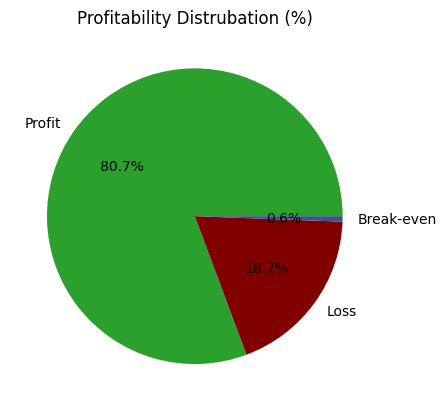

In [14]:
# visualization of profitability distrubation.


profit_counts = df['Profitability Flag'].value_counts (normalize = True) * 100
profit_counts.plot(kind ='pie', autopct='%1.1f%%', colors=['#2ca02c', danger_color, secondary_color])
plt.ylabel('')
plt.title('Profitability Distrubation (%)')
plt.show()

In [15]:
# KPI PERFORMANS INDICATOR


def format_func(value):
    if value >= 1e6:
        return f'${value/1e6:.1f}M'
    elif value >= 1e3:
        return f'${value/1e3:.1f}K'
    else:
        return f'${value:.1f}'

# Correctly align and calculate metrics outside format_func
delayed_df = df[df['Delay'] > 0]
metrics = {}
metrics['Total Orders'] = len(df)
metrics['Late Delivery'] = len(delayed_df)
metrics['90% Delay (days)'] = delayed_df['Delay'].quantile(0.90)
metrics['On time Delivery %'] = (1 - float(metrics['Late Delivery'] / metrics['Total Orders'])) * 100
metrics['Late Delivery %'] = float(metrics['Late Delivery'] / metrics['Total Orders']) * 100
metrics['Total Profit'] = format_func(df.loc[df['Order Profit Per Order'] > 0, 'Order Profit Per Order'].sum())
metrics['Total loss due to Delays'] = format_func(df.loc[df['Delay'] > 0, 'Order Profit Per Order'].sum())

print('\n------Business KPIs------\n')
for k, v in metrics.items():
    if isinstance(v, float):
        print(f'{k}: {v:.2f}')
    else:
        print(f'{k}: {v}')


------Business KPIs------

Total Orders: 13920
Late Delivery: 7552
90% Delay (days): 3.00
On time Delivery %: 45.75
Late Delivery %: 54.25
Total Profit: $603.8K
Total loss due to Delays: $151.5K


In [16]:
# PROFITABILITY VS DELIVERY TIME ANALYSIS #

profit_metrics = df.groupby('Delay')['Order Profit Per Order'].agg(
    mean_profit='mean',
    sum_profit='sum',
    count='count'
).reset_index()

# Display the aggregated metrics
profit_metrics

,Delay,mean_profit,sum_profit,count
0,-2.0,24.844660,46707.960022,1880
1,-1.0,22.591129,40415.530315,1789
2,0.0,21.519248,58058.930007,2698
3,1.0,21.636445,85701.960124,3961
4,2.0,18.345710,44304.889951,2415
5,3.0,18.148830,9927.409983,547
6,4.0,18.325596,11526.800018,629


In [18]:
# dealy distrubation #

delay_distribution = (
    df['Delay']
    .value_counts(normalize=True)
    .sort_index() * 100
).reset_index()

delay_distribution

,Delay,proportion
0,-2.0,13.506717
1,-1.0,12.852935
2,0.0,19.383576
3,1.0,28.457504
4,2.0,17.350384
5,3.0,3.929880
6,4.0,4.519003



Profit Metrics by Delay Days:


,Delay,mean_profit,sum_profit,count
0,-2.0,24.8,46708.0,1880
1,-1.0,22.6,40415.5,1789
2,0.0,21.5,58058.9,2698
3,1.0,21.6,85702.0,3961
4,2.0,18.3,44304.9,2415
5,3.0,18.1,9927.4,547
6,4.0,18.3,11526.8,629



Delay Distribution:


,Delays,Percentage
0,-2.0,13.506717
1,-1.0,12.852935
2,0.0,19.383576
3,1.0,28.457504
4,2.0,17.350384
5,3.0,3.929880
6,4.0,4.519003


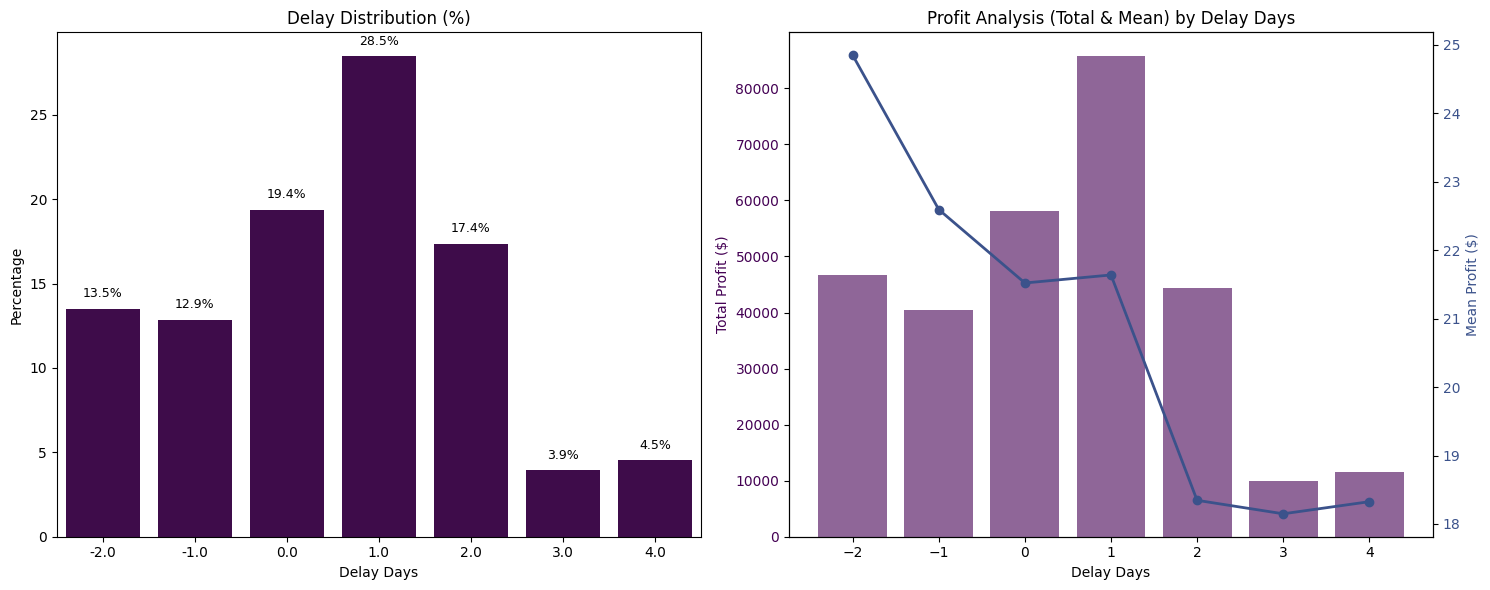

In [19]:
# PROFITABILITY ANALYSIS

delay_distribution.columns = ['Delays', 'Percentage']

print("\nProfit Metrics by Delay Days:")
display(profit_metrics.round(1))

print("\nDelay Distribution:")
display(delay_distribution)

# Corrected to plt.subplots (with an 's')
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

# First subplot: Delay Distribution
# Corrected the dataset typo 'delay_distributio' to 'delay_distribution'
# Corrected the x-column 'Delay_days' to 'Delays'
sns.barplot(x='Delays', y='Percentage', data=delay_distribution, color=primary_color, ax=ax1)
ax1.set_title('Delay Distribution (%)')
ax1.set_xlabel('Delay Days')
ax1.set_ylabel('Percentage')

# Add percentage text on bars
for bar in ax1.patches:
    height = bar.get_height()
    ax1.text(bar.get_x() + bar.get_width()/2, height + 0.5, f'{height:.1f}%', ha='center', va='bottom', fontsize=9)

# Second subplot: Profit analysis by delays (Dual Y-Axis)
# Corrected 'ax2.set.ylabel' to 'ax2.set_ylabel'
ax2.set_ylabel("Total Profit ($)", color=primary_color)
ax2.bar(profit_metrics['Delay'], profit_metrics['sum_profit'], color=primary_color, alpha=0.6, label='Total Profit')
ax2.tick_params(axis='y', labelcolor=primary_color)

# Secondary axis for the Mean Profit line trend
ax3 = ax2.twinx()
ax3.set_ylabel("Mean Profit ($)", color=secondary_color)
# Changed .bar to .plot since 'marker' is used for lines
ax3.plot(profit_metrics['Delay'], profit_metrics['mean_profit'], marker='o', color=secondary_color, linewidth=2, label='Mean Profit')
ax3.tick_params(axis='y', labelcolor=secondary_color)

ax2.set_xlabel("Delay Days")
ax2.set_title('Profit Analysis (Total & Mean) by Delay Days')

plt.tight_layout()
plt.show()

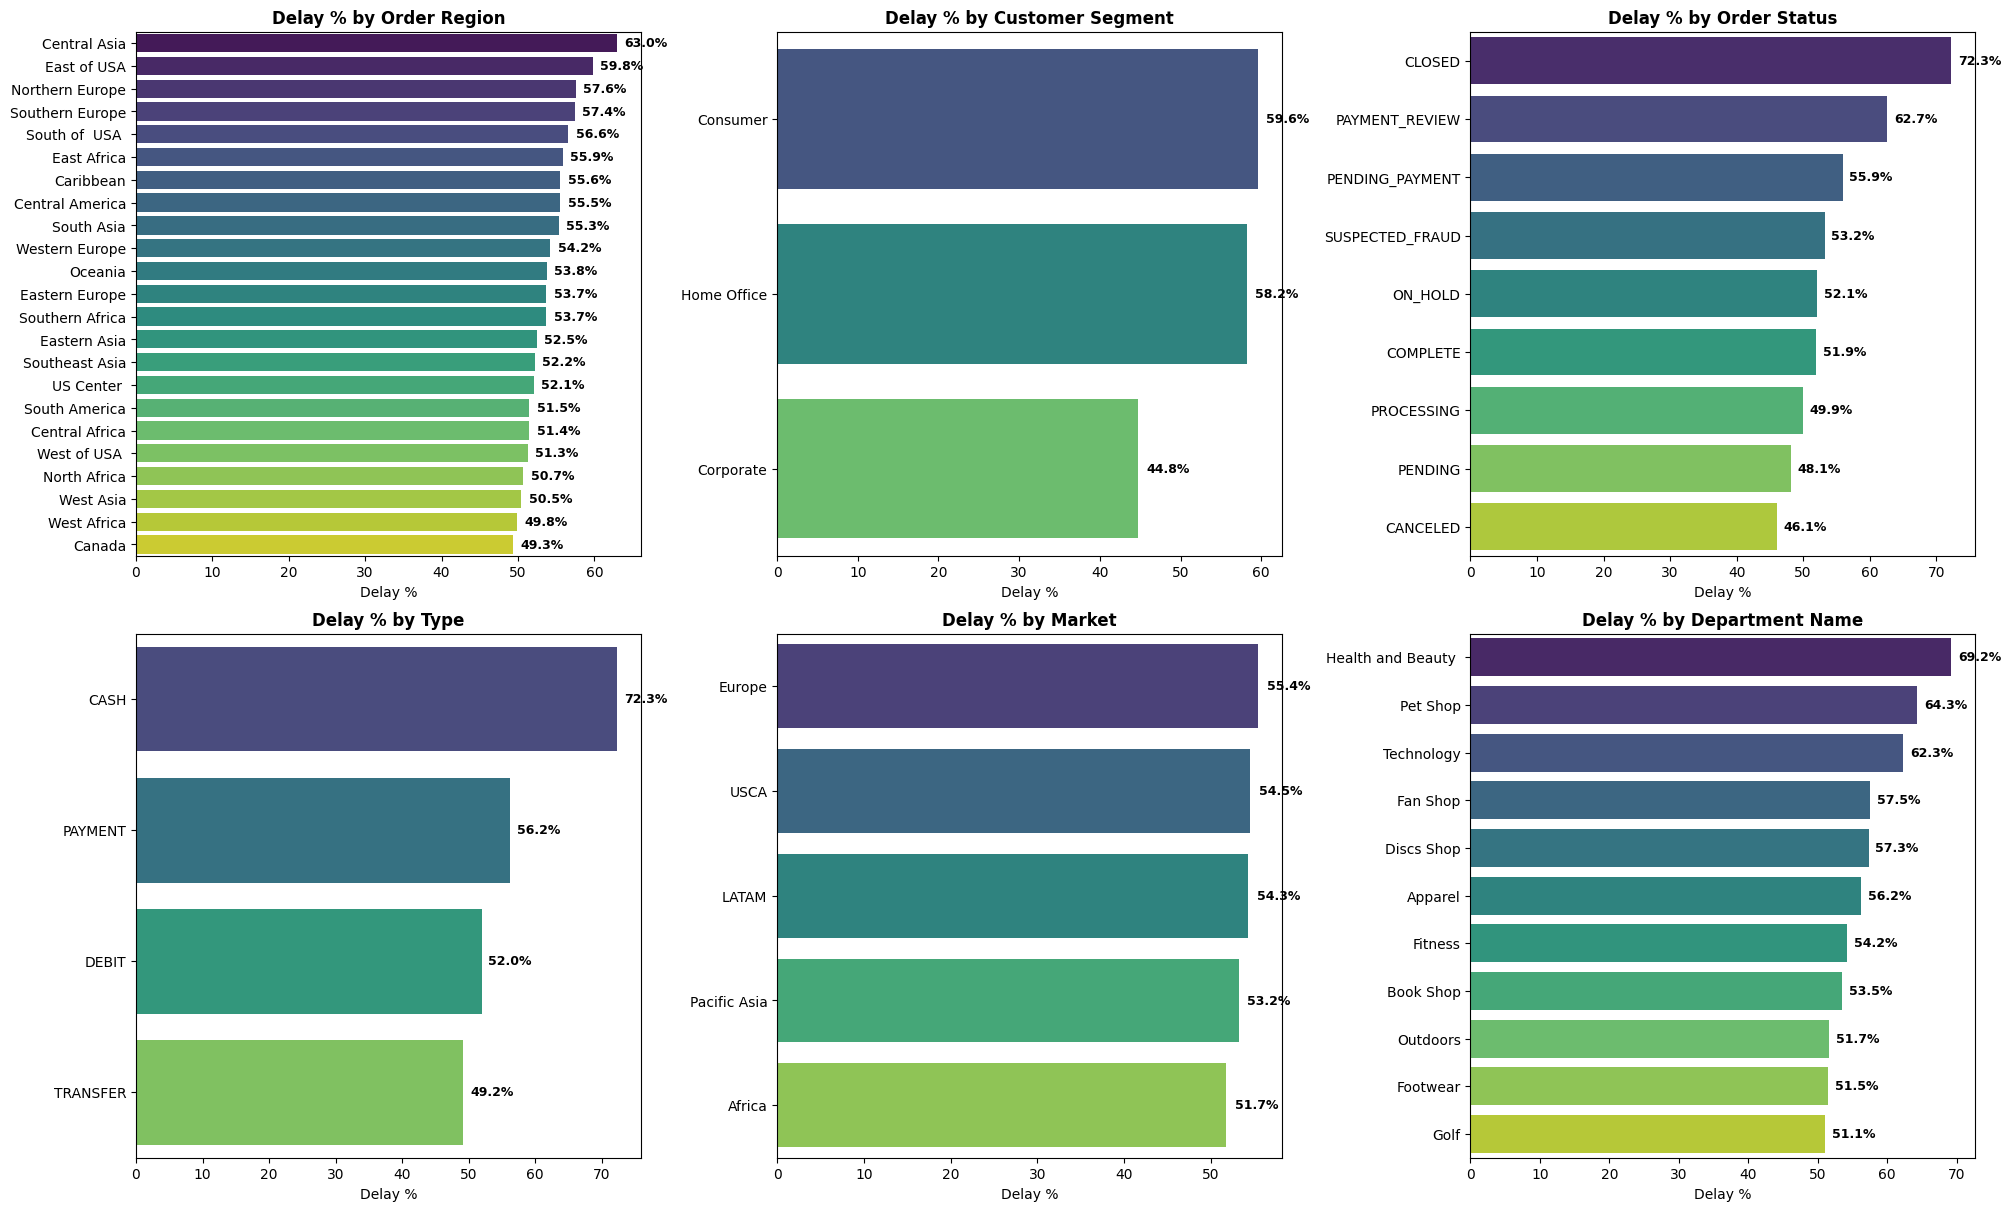

In [20]:
# BOTELNECK DETECTION

def compute_delay_pct_by_category(category):
    cat_df = df.groupby(category).agg(
        total_orders=('Delay', 'count'),
        late_orders=('IS_Delayed', 'sum')
    ).reset_index()

    cat_df['delay_pct'] = (cat_df['late_orders'] / cat_df['total_orders']) * 100
    return cat_df.sort_values('delay_pct', ascending=False)

# Corrected categories with exact matching column names (casing sensitive)
categories = ['Order Region', 'Customer Segment', 'Order Status', 'Type', 'Market', 'Department Name']

# Adjusted layout to 2x3 to accommodate all 6 categories
fig, axes = plt.subplots(2, 3, figsize=(20, 12), constrained_layout=True)
axes = axes.flatten()

for ax, category in zip(axes, categories):
    cat_df = compute_delay_pct_by_category(category)
    sns.barplot(
        data=cat_df,
        x='delay_pct',
        y=category,
        ax=ax,
        palette='viridis'
    )

    ax.set_title(f'Delay % by {category}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Delay %')
    ax.set_ylabel('')

    # Display percentage text on bars
    for i, row in cat_df.reset_index().iterrows():
        val = row['delay_pct']
        ax.text(val + 1, i, f"{val:.1f}%", va='center', fontsize=9, color='black', fontweight='semibold')

plt.show()

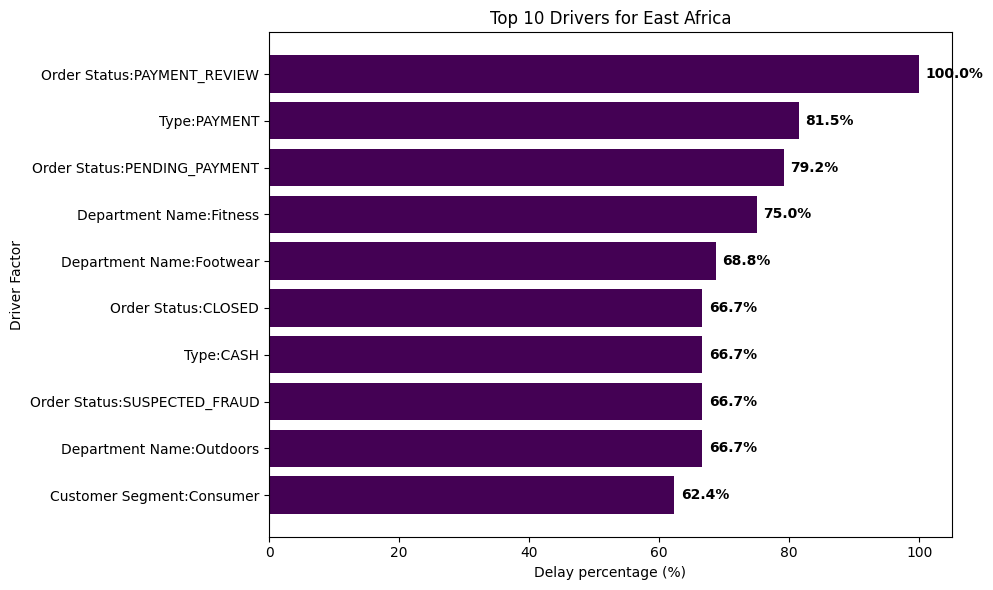

In [21]:
# ROOT CAUSE ANALYSIS

def top_drivers_for_region (region):
  df_region = df[df['Order Region']== region].copy()

  # Removed 'Shipping Mode' since it was dropped in the cleaning step,
  # and corrected casing for the other columns.
  drivers = ['Customer Segment', 'Department Name', 'Type', 'Order Status']

  all_factors = []
  for factor in drivers :
    temp = df_region.groupby(factor).agg(
        total_orders = ('Delay','count'),
        late_orders = ('IS_Delayed','sum')
    ).reset_index()

    temp['delay_pct'] = (temp['late_orders']/temp['total_orders'])*100
    temp['Driver'] = factor
    temp['Factor_level'] = factor + ":" + temp[factor].astype(str)

    # Only select columns that actually exist
    all_factors.append(temp[['Driver','Factor_level','delay_pct','total_orders']])

  # Combine all drivers outside the loop
  final_df = pd.concat(all_factors)

  # Top 10 drivers
  top_factors = final_df.sort_values('delay_pct',ascending=False).head(10)
  plt.figure(figsize=(10, 6))

  bars = plt.barh(top_factors['Factor_level'], top_factors['delay_pct'], color=primary_color)

  plt.xlabel("Delay percentage (%)")
  plt.ylabel("Driver Factor")
  plt.title(f"Top 10 Drivers for {region}")
  plt.gca().invert_yaxis()

  for bar in bars:
    width = bar.get_width()
    plt.text(width + 1, bar.get_y() + bar.get_height()/2,
             f"{width:.1f}%",
             va='center', fontsize = 10 , color = 'black', fontweight='bold')

  plt.tight_layout()
  plt.show()

top_drivers_for_region('East Africa')

In [22]:
# delay % by month day of week . hour

delay_by_month = (
    df.groupby('Order_month')['IS_Delayed'].mean()
).reset_index()


delay_by_month['delay_pct']=delay_by_month['IS_Delayed'] *100


delay_by_day = (
    df.groupby('Order_day')['IS_Delayed'].mean()
).reset_index()

delay_by_day['delay_pct']=delay_by_day['IS_Delayed'] *100

delay_by_hour = (
    df.groupby('Order_hour')['IS_Delayed'].mean()
).reset_index()

delay_by_hour['delay_pct']=delay_by_hour['IS_Delayed'] *100


In [23]:
delay_by_hour

,Order_hour,IS_Delayed,delay_pct
0,0.0,0.500000,50.000000
1,1.0,0.542962,54.296161
2,2.0,0.500821,50.082102
3,3.0,0.554422,55.442177
4,4.0,0.529730,52.972973
5,5.0,0.522538,52.253756
6,6.0,0.565455,56.545455
7,7.0,0.531876,53.187614
8,8.0,0.517647,51.764706
9,9.0,0.570715,57.071547


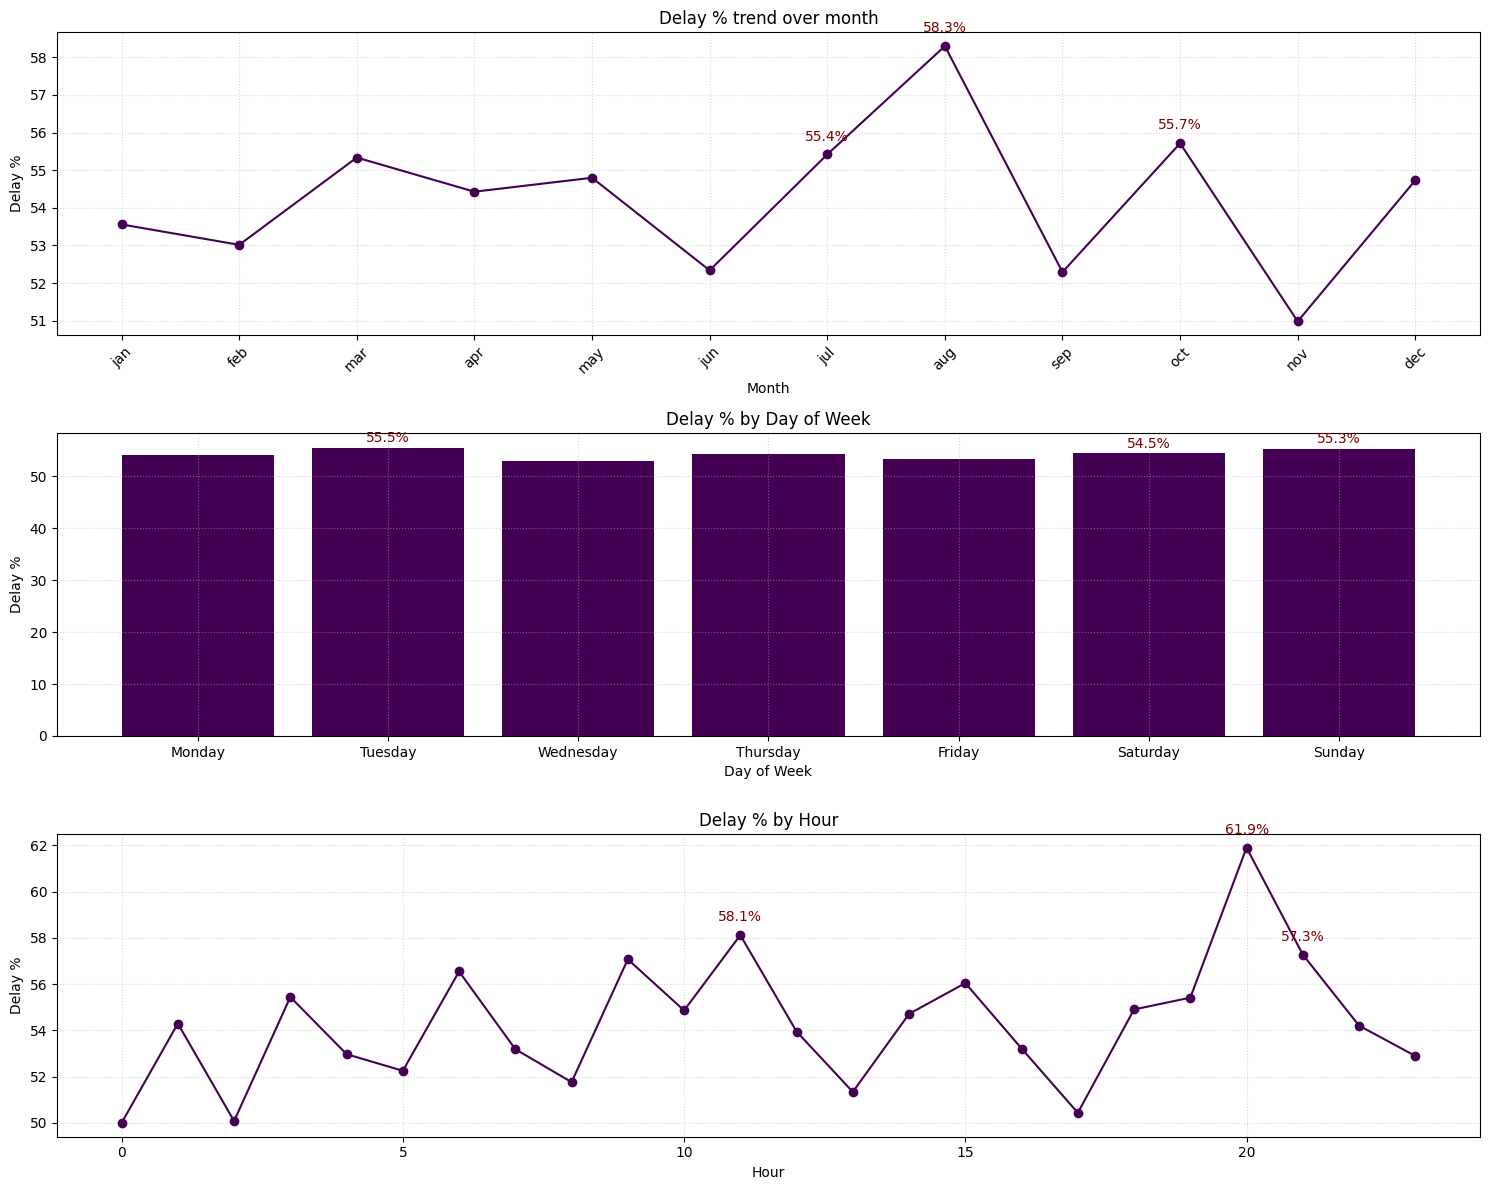

In [26]:

# TIME-BASED DELAY PATTERNS


import matplotlib.pyplot as plt

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(15, 12))

# Subplot 1: Delay % trend over month
ax1.plot(delay_by_month['Order_month'], delay_by_month['delay_pct'], marker='o', color=primary_color)
ax1.set_title('Delay % over Month')
ax1.set_xticks(range(1, 13))
ax1.set_xticklabels(['jan', 'feb', 'mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec'], rotation=45)
ax1.set_xlabel("Month")
ax1.set_ylabel("Delay %")
ax1.set_title("Delay % trend over month")
ax1.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest months
top3_month = delay_by_month.nlargest(3, 'delay_pct')
for _, row in top3_month.iterrows():
    ax1.annotate(f"{row['delay_pct']:.1f}%", (row['Order_month'], row['delay_pct']),
                 textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, color=danger_color)

# Subplot 2: Delay % by day of week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
delay_by_day['Order_day'] = pd.Categorical(delay_by_day['Order_day'], categories=day_order, ordered=True)
delay_by_day = delay_by_day.sort_values('Order_day')

ax2.bar(delay_by_day['Order_day'], delay_by_day['delay_pct'], color=primary_color)
ax2.set_title('Delay % by Day of Week')
ax2.set_xlabel("Day of Week")
ax2.set_ylabel("Delay %")
ax2.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest days
top3_days = delay_by_day.nlargest(3, 'delay_pct')
for _, row in top3_days.iterrows():
    height = row['delay_pct']
    ax2.text(row['Order_day'], height + 0.5, f'{height:.1f}%', ha='center', va='bottom', fontsize=10, color=danger_color)

# Subplot 3: Delay % by hour
ax3.plot(delay_by_hour['Order_hour'], delay_by_hour['delay_pct'], marker='o', color=primary_color)
ax3.set_title('Delay % by Hour')
ax3.set_xlabel("Hour")
ax3.set_ylabel("Delay %")
ax3.grid(True, linestyle=':', alpha=0.5)

# Annotate top 3 highest hours
top3_hour = delay_by_hour.nlargest(3, 'delay_pct')
for _, row in top3_hour.iterrows():
    ax3.annotate(f"{row['delay_pct']:.1f}%", (row['Order_hour'], row['delay_pct']),
                 textcoords="offset points", xytext=(0, 10), ha="center", fontsize=10, color=danger_color)

plt.tight_layout()
plt.show()

In [ ]:
# MACHINE LEARNING MODEL

In [30]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report
from sklearn.ensemble import RandomForestClassifier
from collections import Counter
from imblearn.over_sampling import SMOTE

In [34]:
# Corrected column names to match the DataFrame (df)
x = df[['Type', 'Days for shipment (scheduled)', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region', 'Order_month', 'Order_hour']]
y = df['Late_delivery_risk']

In [36]:
# Corrected 'includes' to 'include' and 'Object' to 'object'
cat_cols = x.select_dtypes(include = ['object','category']).columns.tolist()
print('Categorical columns :',cat_cols)

# frequency encoding (low-dimensional and robust for high-cardinality)
for col in cat_cols:
  freq = x[col].value_counts(normalize=True)
  x[col] = x[col].map(freq)

# keep numeric columns + new encoded features , drop original string categories
x_encoded = x.drop(columns=cat_cols)
print('Shape after freq + target encoding:' , x_encoded.shape)

# use encoded features for modeling
x = x_encoded

# train/test split after encoding
x_train, x_test, y_train, y_test = train_test_split(
  x, y, test_size=0.2, random_state = 42, stratify=y
)

Categorical columns : ['Type', 'Category Name', 'Customer Segment', 'Department Name', 'Order Region']
Shape after freq + target encoding: (13920, 3)


In [37]:
x_encoded

,Days for shipment (scheduled),Order_month,Order_hour
0,4,1.0,22.0
1,4,1.0,12.0
2,4,1.0,12.0
3,4,1.0,11.0
4,4,1.0,11.0
...,...,...,...
13915,4,8.0,8.0
13916,4,10.0,9.0
13917,4,6.0,8.0
13918,4,12.0,11.0


In [38]:
y.value_counts()

,count
Late_delivery_risk,
1,7379
0,6541


In [40]:
# Handling NaNs first by filling them with the median of each column
x_train_imputed = x_train.fillna(x_train.median())
x_test_imputed = x_test.fillna(x_train.median()) # Impute test using train median to avoid leakage

# Balancing the training data using SMOTE
print("Before balancing (train):", Counter(y_train))

smote = SMOTE(random_state=42)
x_train_balanced, y_train_balanced = smote.fit_resample(x_train_imputed, y_train)

print("After balancing (train):", Counter(y_train_balanced))

Before balancing (train): Counter({1: 5903, 0: 5233})
After balancing (train): Counter({0: 5903, 1: 5903})


In [47]:
def evaluate_model(y_true, y_pred, model_name):
  print(f"\n---{model_name}-----")
  print("Accuracy:", accuracy_score(y_true, y_pred))
  print("Precision:", precision_score(y_true, y_pred))
  print("Recall:", recall_score(y_true, y_pred))
  # Corrected spelling from 'Classification_reportely' to 'classification_report'
  print("\nClassification Report:\n", classification_report(y_true, y_pred))

In [48]:
# fit random forest model on balanced data

rf_model_balanced = RandomForestClassifier(random_state=42)
rf_model_balanced.fit(x_train_balanced, y_train_balanced)

y_pred_rf_balanced = rf_model_balanced.predict(x_test_imputed)

# Corrected the typo 'evaluate_mode' to 'evaluate_model'
evaluate_model(y_test, y_pred_rf_balanced, "Random Forest Classifier")


---Random Forest Classifier-----
Accuracy: 0.6900143678160919
Precision: 0.7888784165881244
Recall: 0.5670731707317073

Classification Report:
               precision    recall  f1-score   support

           0       0.63      0.83      0.72      1308
           1       0.79      0.57      0.66      1476

    accuracy                           0.69      2784
   macro avg       0.71      0.70      0.69      2784
weighted avg       0.71      0.69      0.69      2784

